<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/02_teoria_y_metricas_rl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 02 · Aprendizaje por Refuerzo: conceptos, algoritmos y **métricas**
**Machine Learning — Duoc UC, Escuela de Informática y Telecomunicaciones**

Este notebook es para **explicar en clase** (se ejecuta completo, en orden). Al final de la clase los estudiantes deben poder:

1. Formular un problema como MDP (estado, acción, recompensa, transición, descuento).
2. Explicar y comparar **Q-learning** (off-policy) y **SARSA** (on-policy).
3. **Medir** un agente de RL correctamente: curvas con varias semillas, intervalos de confianza, eficiencia muestral, éxito, costo/seguridad, *regret* y evaluación *greedy* separada del entrenamiento.

> Archivos: `rl_utils.py` (entorno + agentes + métricas) y `../data/runs_cliffwalking.csv` (25.000 episodios ya entrenados: 5 configuraciones × 10 semillas × 500 episodios).
### Para llegar con el vocabulario
18 minutos, inglés con subtítulos en español: [StatQuest — Reinforcement Learning: Essential Concepts](https://www.youtube.com/watch?v=Z-T0iJEXiwM). Si ya vieron la grilla del notebook 01, este video pone nombre a lo que acabaron de ver.

En español, para después: [Codificando Bits, nivel básico](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-basico/). El libro gratuito es Sutton y Barto, [2.ª ed.](http://incompleteideas.net/book/the-book-2nd.html). Cliff Walking es el ejemplo 6.6.


In [1]:
#@title ⚙️ Configuración (ejecutar primero — en Colab clona el repositorio, sin subir archivos)
import os, sys, subprocess, glob

REPO_URL = "https://github.com/Giocrisrai/aprendizaje-refuerzo-duoc"
EN_COLAB = "google.colab" in sys.modules
ARCHIVOS = ("rl_utils.py", "salmon_env.py", "grilla.py", "evolucion.py")
DATOS = (
    "../data/runs_cliffwalking.csv",
    "../data/historial_inventario.csv",
    "../data/historial_operador_salmon.csv",
)

def buscar_notebooks():
    """Carpeta que contiene los .py de la clase, o None."""
    if all(os.path.exists(nombre) for nombre in ARCHIVOS):
        return os.getcwd()
    candidatos = [
        "/content/aprendizaje-refuerzo-duoc/notebooks",
        "/content/rl_aprendizaje_refuerzo/notebooks",
    ]
    candidatos += glob.glob("/content/**/notebooks", recursive=True)
    vistos = []
    for carpeta in candidatos:
        if carpeta in vistos or not os.path.isdir(carpeta):
            continue
        vistos.append(carpeta)
        if all(os.path.exists(os.path.join(carpeta, nombre)) for nombre in ARCHIVOS):
            return carpeta
    return None

if EN_COLAB and buscar_notebooks() is None:
    subprocess.run(
        ["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/aprendizaje-refuerzo-duoc"],
        check=False,
    )

carpeta = buscar_notebooks()
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro " + ", ".join(ARCHIVOS) + ". "
        "En Colab esta celda clona el repositorio: ahí están los módulos y data/. "
        "En el computador, abre el notebook desde la carpeta notebooks/."
    )
os.chdir(carpeta)

if EN_COLAB:
    req = os.path.abspath(os.path.join(os.getcwd(), "..", "requirements.txt"))
    if os.path.exists(req):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", req])
try:
    import numpy, pandas, matplotlib
except ImportError as exc:
    raise ImportError("Faltan numpy, pandas o matplotlib. En local, desde la raíz del repositorio: uv sync --group dev") from exc
faltan = [ruta for ruta in DATOS if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError("Faltan datos del repositorio: " + ", ".join(faltan))
print("✅ Listo. Carpeta de trabajo:", os.getcwd(), "| Colab" if EN_COLAB else "| local")
print("Librerías:", "numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)


✅ Listo. Carpeta de trabajo: /home/claude/rl_clase/notebooks | local


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inspect
from rl_utils import CliffWalking, ACCIONES, entrenar, evaluar_greedy, curva_con_ic, \
    auc_normalizada, episodios_hasta_umbral, regret_acumulado, resumen_metricas, media_movil

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. El problema de RL en una lámina

Un **agente** observa un **estado** $s_t$, elige una **acción** $a_t$, el **entorno** responde con una **recompensa** $r_{t+1}$ y un nuevo estado $s_{t+1}$. No hay etiquetas "correctas": el agente aprende **por ensayo y error** a maximizar el **retorno**:

$$G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots \qquad 0 \le \gamma \le 1$$

| Concepto | Qué es | En CliffWalking |
|---|---|---|
| Estado $s$ | lo que el agente necesita saber para decidir | celda (fila, columna) → 48 estados |
| Acción $a$ | lo que puede hacer | arriba, derecha, abajo, izquierda |
| Recompensa $r$ | señal escalar inmediata | −1 por paso, −100 si cae al acantilado |
| Política $\pi(a\mid s)$ | regla de decisión | lo que queremos aprender |
| Valor de acción $Q^\pi(s,a)$ | retorno esperado si hago $a$ en $s$ y luego sigo $\pi$ | tabla 48 × 4 |

**Ecuación de Bellman de optimalidad** (la idea central de todo lo que sigue):

$$Q^*(s,a) = \mathbb{E}\left[r_{t+1} + \gamma \max_{a'} Q^*(s_{t+1}, a') \;\middle|\; s_t=s, a_t=a\right]$$

Si conociéramos $Q^*$, la política óptima es simplemente $\pi^*(s)=\arg\max_a Q^*(s,a)$.

### Diferencias con aprendizaje supervisado (para preguntar en clase)
- Los datos **dependen de la política**: si el agente explora mal, nunca ve las situaciones importantes.
- La recompensa puede llegar **tarde** (problema de asignación de crédito).
- Hay que balancear **exploración vs. explotación**.

## 2. El entorno: CliffWalking (Sutton & Barto, ejemplo 6.6)

```
fila 0  . . . . . . . . . . . .
fila 1  . . . . . . . . . . . .
fila 2  . . . . . . . . . . . .
fila 3  S C C C C C C C C C C G      S=inicio  C=acantilado (−100)  G=meta
```
El camino más corto (13 pasos, retorno −13) pasa **pegado al acantilado**. Un camino seguro (por arriba) es más largo (~17 pasos) pero no arriesga caer.

In [3]:
env = CliffWalking(seed=0)
s = env.reset()
print("Estado inicial:", s, "-> (fila, col) =", divmod(s, 12))
for a in [0, 1, 1, 2]:
    s, r, done, info = env.step(a)
    print(f"acción={ACCIONES[a]:9s} -> estado={divmod(s, 12)}  r={r:6.1f}  info={info}")

Estado inicial: 36 -> (fila, col) = (3, 0)
acción=arriba    -> estado=(2, 0)  r=  -1.0  info={'cayo': False, 'llego': False}
acción=derecha   -> estado=(2, 1)  r=  -1.0  info={'cayo': False, 'llego': False}
acción=derecha   -> estado=(2, 2)  r=  -1.0  info={'cayo': False, 'llego': False}
acción=abajo     -> estado=(3, 0)  r=-100.0  info={'cayo': True, 'llego': False}


## 3. Algoritmos: Q-learning vs SARSA

En el notebook 01 esa cuenta ya salió con números: pisar el trofeo deja la celda en 500, y el paso de atrás copia $-1 + 0{,}95 \times 500$, a la mitad por el $\alpha$. La fórmula de abajo es la misma. Lo nuevo es que hay dos maneras de armar el objetivo.

Ambos aprenden la tabla $Q(s,a)$ con actualizaciones de **diferencia temporal (TD)**: corrigen la estimación actual hacia un *objetivo* que usa la recompensa observada más la estimación del siguiente estado.

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\underbrace{\text{objetivo} - Q(s,a)}_{\text{error TD } \delta}\big]$$

| | Objetivo | Tipo | Consecuencia |
|---|---|---|---|
| **Q-learning** | $r + \gamma \max_{a'} Q(s',a')$ | *off-policy*: aprende la política **greedy** aunque se comporte con ε-greedy | aprende el camino óptimo (pegado al acantilado) y en entrenamiento **cae seguido** por la exploración |
| **SARSA** | $r + \gamma\, Q(s',a')$ con $a'$ la acción que **realmente** tomará | *on-policy*: aprende el valor de la política que ejecuta (incluida la exploración) | aprende un camino **más seguro** mientras explora |

**ε-greedy**: con probabilidad ε elige una acción al azar (explora); si no, la de mayor Q (explota). Lo usual es **decaer** ε durante el entrenamiento.

Veamos el código real que usaremos (es corto, vale la pena leerlo en voz alta):
Para ver la tabla nacer, con dibujos: [Q-Learning Explained, Serrano.Academy](https://www.youtube.com/watch?v=qhRNvCVVJaA). En español: [SARSA](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/14-control-sarsa/) y [Q-learning](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/15-q-learning/) de Codificando Bits. La clase universitaria es [David Silver, lecture 5](https://www.youtube.com/watch?v=0g4j2k_Ggc4).


In [4]:
from rl_utils import epsilon_greedy
print(inspect.getsource(epsilon_greedy))
src = inspect.getsource(entrenar)
print(src[src.index("        while not done:"):src.index("            td_abs.append")])

def epsilon_greedy(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1])), True
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max()))), False

        while not done:
            s2, r, done, info = env.step(a)
            a2, expl2 = epsilon_greedy(Q, s2, eps, rng)
            if algoritmo == "q_learning":
                objetivo = r + (0 if info["llego"] else gamma * Q[s2].max())
            elif algoritmo == "sarsa":
                objetivo = r + (0 if info["llego"] else gamma * Q[s2, a2])
            else:
                objetivo = Q[s, a]
            td = objetivo - Q[s, a]
            if algoritmo != "aleatorio":
                Q[s, a] += alpha * td



## 4. Entrenamiento en vivo y lectura de lo aprendido
Entrenamos un Q-learning y un SARSA con ε fijo = 0.1 (como en el libro) para ver la diferencia de comportamiento.

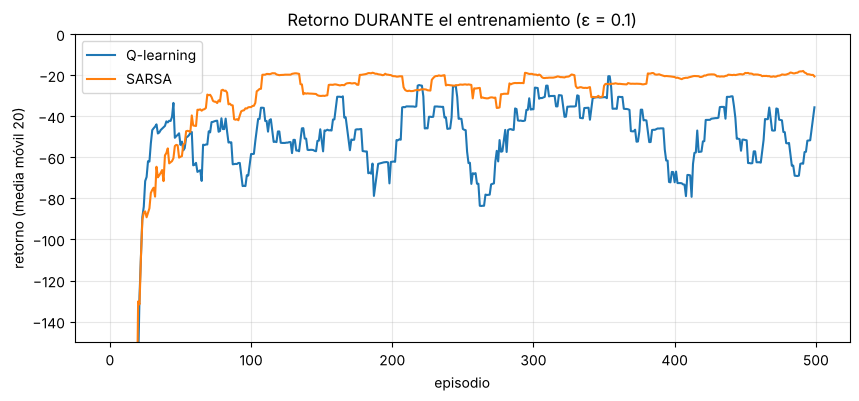

In [5]:
Q_ql, log_ql = entrenar("q_learning", n_episodios=500, eps_inicial=0.1, decaimiento=False, seed=1)
Q_sa, log_sa = entrenar("sarsa", n_episodios=500, eps_inicial=0.1, decaimiento=False, seed=1)

fig, ax = plt.subplots()
ax.plot(media_movil(log_ql.retorno, 20), label="Q-learning")
ax.plot(media_movil(log_sa.retorno, 20), label="SARSA")
ax.set_ylim(-150, 0); ax.set_xlabel("episodio"); ax.set_ylabel("retorno (media móvil 20)")
ax.set_title("Retorno DURANTE el entrenamiento (ε = 0.1)"); ax.legend();

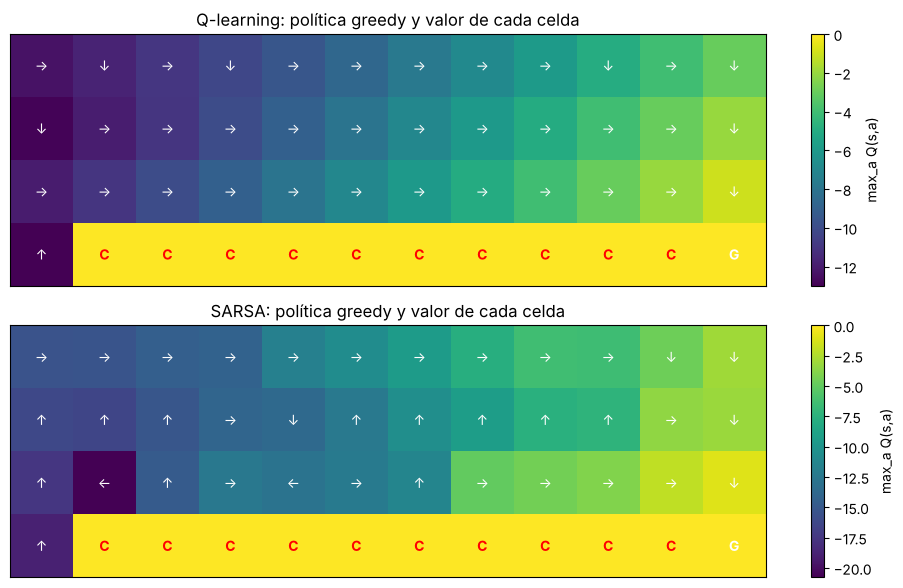

In [6]:
FLECHAS = {0: "↑", 1: "→", 2: "↓", 3: "←"}

def dibujar_politica(Q, titulo, ax):
    V = Q.max(axis=1).reshape(4, 12)
    im = ax.imshow(V, cmap="viridis")
    for f in range(4):
        for c in range(12):
            if f == 3 and 1 <= c <= 10:
                ax.text(c, f, "C", ha="center", va="center", color="red", fontweight="bold")
            elif (f, c) == (3, 11):
                ax.text(c, f, "G", ha="center", va="center", color="white", fontweight="bold")
            else:
                ax.text(c, f, FLECHAS[int(Q[f * 12 + c].argmax())], ha="center", va="center", color="white")
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.015, label="max_a Q(s,a)")

fig, axs = plt.subplots(2, 1, figsize=(10, 6))
dibujar_politica(Q_ql, "Q-learning: política greedy y valor de cada celda", axs[0])
dibujar_politica(Q_sa, "SARSA: política greedy y valor de cada celda", axs[1])
plt.tight_layout()

**Pregunta para la clase:** según el gráfico de entrenamiento, SARSA "gana". Según las flechas, Q-learning aprendió el camino más corto. ¿Quién es mejor?

→ Depende de **qué se mide y cuándo**. Esto motiva toda la sección de métricas: hay que distinguir el **desempeño durante el entrenamiento** (incluye la exploración, importa si entrenar es caro o riesgoso) del **desempeño de la política final** (evaluación greedy, sin explorar).

In [7]:
print("Evaluación greedy (ε=0, sin aprender, 20 episodios):")
print("  Q-learning:", evaluar_greedy(Q_ql).mean())
print("  SARSA     :", evaluar_greedy(Q_sa).mean())

Evaluación greedy (ε=0, sin aprender, 20 episodios):
  Q-learning: -13.0
  SARSA     : -17.0


## 5. Métricas para evaluar agentes de RL

Trabajamos ahora con el dataset `runs_cliffwalking.csv`: 5 configuraciones × 10 semillas × 500 episodios.

| columna | significado |
|---|---|
| `algoritmo` | aleatorio, q_learning, sarsa (ε decae 0.3→0.01), q_learning_eps_fijo, sarsa_eps_fijo (ε=0.1) |
| `seed` | semilla (repetición independiente) |
| `retorno` | suma de recompensas del episodio |
| `largo`, `exito`, `caidas` | pasos, si llegó a la meta, cuántas veces cayó |
| `epsilon`, `frac_exploracion` | exploración programada y la realmente ejecutada |
| `td_error_medio` | magnitud media del error TD en el episodio (diagnóstico de convergencia) |

In [8]:
runs = pd.read_csv("../data/runs_cliffwalking.csv")
print(runs.shape)
runs.head()

(25000, 10)


,algoritmo,seed,episodio,retorno,largo,exito,caidas,epsilon,frac_exploracion,td_error_medio
0,aleatorio,0,0,-1685.0,200,0,15,1.0,1.0,0.0
1,aleatorio,0,1,-2081.0,200,0,19,1.0,1.0,0.0
2,aleatorio,0,2,-1487.0,200,0,13,1.0,1.0,0.0
3,aleatorio,0,3,-1883.0,200,0,17,1.0,1.0,0.0
4,aleatorio,0,4,-1685.0,200,0,15,1.0,1.0,0.0


### 5.1 Retorno por episodio: crudo vs media móvil
Las curvas de RL son **muy ruidosas**. Siempre se suavizan (media móvil) y se dice explícitamente el tamaño de ventana.

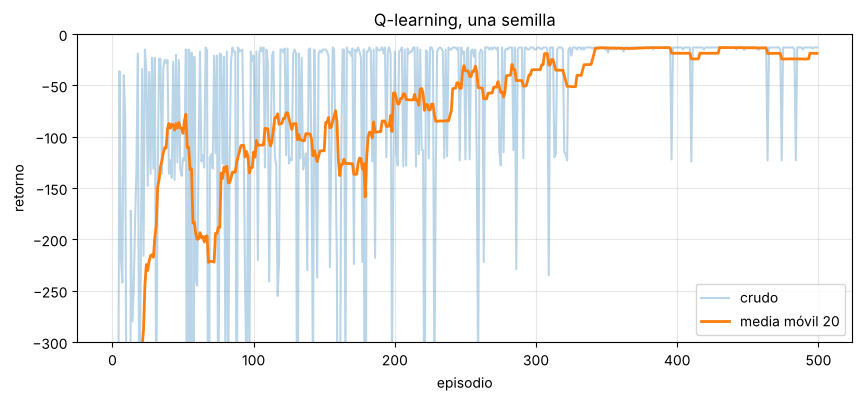

In [9]:
una = runs.query("algoritmo == 'q_learning' and seed == 0")
fig, ax = plt.subplots()
ax.plot(una.episodio, una.retorno, alpha=0.3, label="crudo")
ax.plot(una.episodio, media_movil(una.retorno, 20), lw=2, label="media móvil 20")
ax.set_ylim(-300, 0); ax.set_xlabel("episodio"); ax.set_ylabel("retorno"); ax.legend()
ax.set_title("Q-learning, una semilla");

### 5.2 Variabilidad entre semillas: nunca reportar una sola corrida
Una semilla puede tener suerte. Se reporta la **media entre semillas** con un **intervalo de confianza 95%**:

$$\bar{x} \pm 1.96\,\frac{s}{\sqrt{n}} \qquad (n = \text{número de semillas})$$

Si los intervalos de dos algoritmos se solapan mucho, **no podemos afirmar** que uno es mejor.

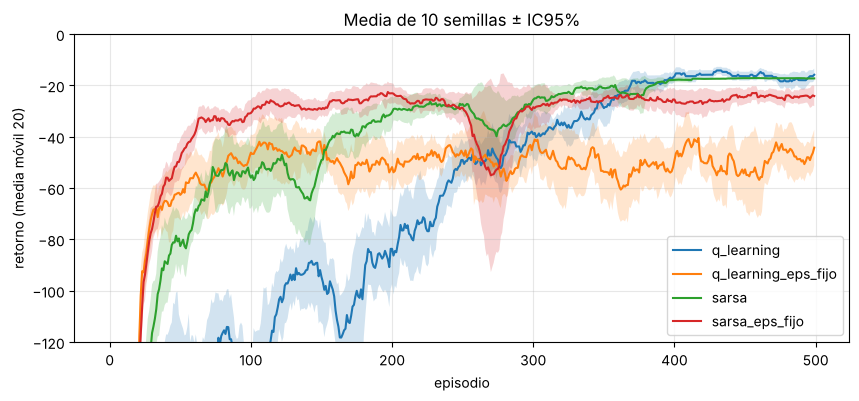

In [10]:
agg = curva_con_ic(runs.query("algoritmo != 'aleatorio'"), ventana=20)
fig, ax = plt.subplots()
for alg, g in agg.groupby("algoritmo"):
    ax.plot(g.episodio, g["mean"], label=alg)
    ax.fill_between(g.episodio, g["mean"] - g.ic, g["mean"] + g.ic, alpha=0.2)
ax.set_ylim(-120, 0); ax.set_xlabel("episodio"); ax.set_ylabel("retorno (media móvil 20)")
ax.set_title("Media de 10 semillas ± IC95%"); ax.legend();

### 5.3 Éxito y costo/seguridad
El retorno resume todo en un número; en problemas reales conviene reportar también **métricas operativas**: tasa de éxito y número de eventos indeseados (aquí: caídas al acantilado). Dos agentes con retorno parecido pueden tener perfiles de riesgo muy distintos.

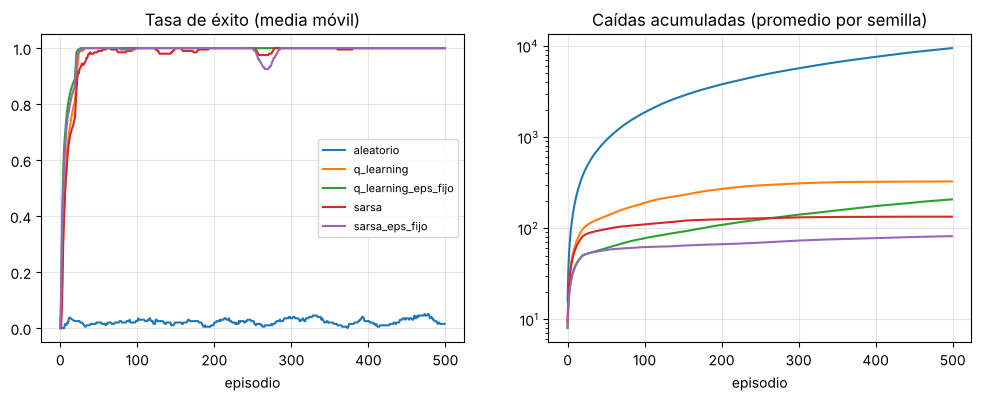

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for alg, g in runs.groupby("algoritmo"):
    m = g.groupby("episodio")[["exito", "caidas"]].mean()
    axs[0].plot(media_movil(m.exito, 20), label=alg)
    axs[1].plot(media_movil(m.caidas, 20).cumsum(), label=alg)
axs[0].set_title("Tasa de éxito (media móvil)"); axs[0].set_xlabel("episodio")
axs[1].set_title("Caídas acumuladas (promedio por semilla)"); axs[1].set_xlabel("episodio"); axs[1].set_yscale("log")
axs[0].legend(fontsize=8);

### 5.4 Eficiencia muestral: AUC y episodios hasta umbral
- **AUC normalizada**: área bajo la curva de aprendizaje, escalada a [0,1] entre un retorno mínimo y el óptimo. Premia aprender **rápido** y **bien**.
- **Episodios hasta umbral**: primer episodio en que la media móvil supera un nivel aceptable (aquí −30). Útil cuando cada episodio es caro (robots, procesos industriales, una temporada de cultivo...).

### 5.5 Regret acumulado
$$\text{Regret}(N) = \sum_{k=1}^{N} \big(G^* - G_k\big)$$
Lo que se dejó de ganar respecto al óptimo (−13) mientras se aprendía. Un regret que deja de crecer = el agente ya se comporta casi óptimo **durante** el entrenamiento.

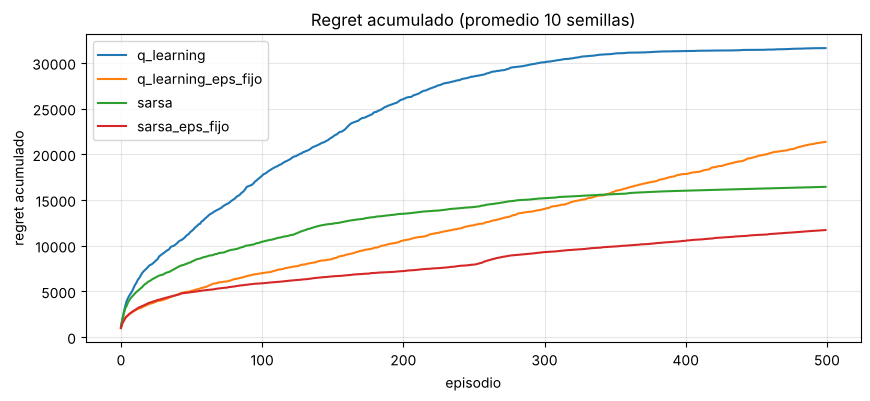

In [12]:
fig, ax = plt.subplots()
for alg, g in runs.query("algoritmo != 'aleatorio'").groupby("algoritmo"):
    reg = np.mean([regret_acumulado(gs.sort_values("episodio").retorno, -13) for _, gs in g.groupby("seed")], axis=0)
    ax.plot(reg, label=alg)
ax.set_xlabel("episodio"); ax.set_ylabel("regret acumulado"); ax.set_title("Regret acumulado (promedio 10 semillas)"); ax.legend();

### 5.6 Tabla resumen (así se reporta)
Por semilla calculamos las métricas y luego agregamos media ± IC95%.

In [13]:
res = resumen_metricas(runs)
def media_ic(x, d=1):
    x = x.dropna()
    return f"{x.mean():.{d}f} ± {1.96 * x.std(ddof=1) / np.sqrt(len(x)):.{d}f}" if len(x) > 1 else "—"
tabla = res.groupby("algoritmo").agg(
    retorno_ult50=("retorno_final", media_ic),
    exito_ult50=("exito_final", "mean"),
    auc=("auc", lambda x: media_ic(x, 3)),
    ep_hasta_umbral=("ep_hasta_umbral", media_ic),
    regret_total=("regret_total", media_ic),
    caidas_totales=("caidas_totales", media_ic),
)
tabla

,retorno_ult50,exito_ult50,auc,ep_hasta_umbral,regret_total,caidas_totales
algoritmo,,,,,,
aleatorio,-2046.4 ± 53.4,0.03,0.002 ± 0.001,—,1030126.1 ± 9468.4,9470.2 ± 95.8
q_learning,-16.7 ± 1.8,1.00,0.774 ± 0.008,263.7 ± 26.8,31614.1 ± 1593.5,271.2 ± 15.2
q_learning_eps_fijo,-46.0 ± 4.8,1.00,0.808 ± 0.008,120.3 ± 35.3,21353.6 ± 855.2,176.6 ± 8.0
sarsa,-17.2 ± 0.1,1.00,0.871 ± 0.014,136.8 ± 26.7,16435.9 ± 1514.6,84.7 ± 7.5
sarsa_eps_fijo,-24.0 ± 2.1,1.00,0.895 ± 0.012,63.9 ± 6.8,11709.3 ± 1259.8,50.1 ± 4.7


### 5.7 Entrenamiento ≠ evaluación
El retorno en los últimos episodios de entrenamiento **incluye exploración**. La política aprendida se evalúa aparte con ε = 0 y **semillas distintas** a las de entrenamiento.

In [14]:
filas = []
for alg, kw in [("q_learning_eps_fijo", dict(algoritmo="q_learning", decaimiento=False, eps_inicial=0.1)),
                ("sarsa_eps_fijo", dict(algoritmo="sarsa", decaimiento=False, eps_inicial=0.1))]:
    for seed in range(5):
        Q, log = entrenar(n_episodios=500, seed=seed, **kw)
        filas.append(dict(algoritmo=alg, seed=seed,
                          entrenamiento_ult50=log.retorno.tail(50).mean(),
                          evaluacion_greedy=evaluar_greedy(Q, seed=1000 + seed).mean()))
pd.DataFrame(filas).groupby("algoritmo")[["entrenamiento_ult50", "evaluacion_greedy"]].mean().round(1)

,entrenamiento_ult50,evaluacion_greedy
algoritmo,,
q_learning_eps_fijo,-50.4,-13.0
sarsa_eps_fijo,-24.3,-17.0


### 5.8 Diagnóstico: ¿está aprendiendo o solo explorando?
- `epsilon` programado vs `frac_exploracion` ejecutada.
- `td_error_medio`: si no baja, los valores no se estabilizan (α muy alto, recompensas muy ruidosas, estado mal diseñado...).

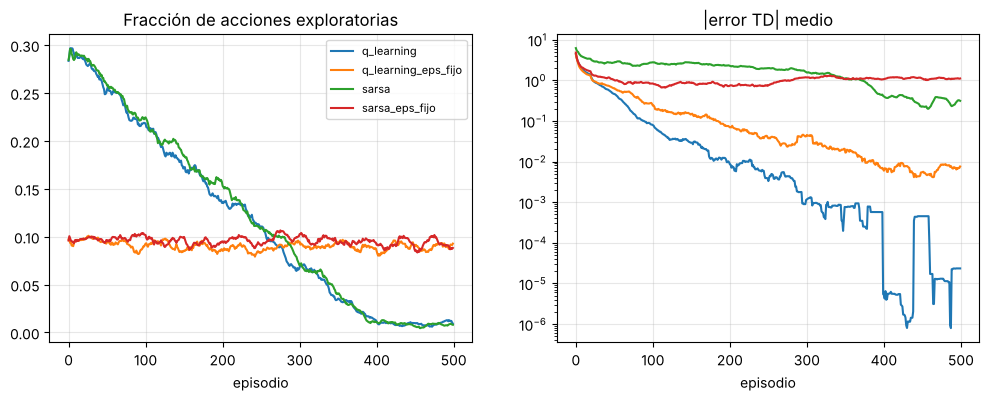

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for alg, g in runs.query("algoritmo != 'aleatorio'").groupby("algoritmo"):
    m = g.groupby("episodio")[["frac_exploracion", "td_error_medio"]].mean()
    axs[0].plot(media_movil(m.frac_exploracion, 20), label=alg)
    axs[1].plot(media_movil(m.td_error_medio, 20), label=alg)
axs[0].set_title("Fracción de acciones exploratorias"); axs[1].set_title("|error TD| medio"); axs[1].set_yscale("log")
for a in axs: a.set_xlabel("episodio")
axs[0].legend(fontsize=8);

## 6. Resumen: checklist para reportar un experimento de RL
1. **≥ 5 semillas** por configuración; reportar media ± IC95%.
2. Curva de aprendizaje suavizada (indicar ventana) **con banda de confianza**.
3. Separar **retorno en entrenamiento** de **evaluación greedy** en semillas nuevas.
4. Métricas operativas además del retorno (éxito, eventos indeseados, costo).
5. Eficiencia muestral (AUC, episodios/pasos hasta umbral) y **presupuesto de interacciones** usado.
6. Comparar contra **líneas base** (aleatoria y una heurística razonable). Un agente que no supera una regla simple no sirve.

### Preguntas para discutir
- ¿Por qué con ε fijo Q-learning tiene peor retorno de entrenamiento pero mejor política greedy?
- Si cada episodio fuera una temporada productiva real (meses), ¿qué métrica priorizarías?
- ¿Qué pasa con SARSA vs Q-learning cuando ε → 0? (mirar `q_learning` vs `sarsa` con decaimiento)
### Para repasar esta clase
| Tema | Dónde |
|---|---|
| Agente, recompensa, política (18 min) | [StatQuest](https://www.youtube.com/watch?v=Z-T0iJEXiwM) |
| La grilla, antes de los intervalos | Notebook 01 |
| Q-learning con una tabla que se ve | [Serrano.Academy](https://www.youtube.com/watch?v=qhRNvCVVJaA) |
| SARSA y Q-learning, en español | [Lección 14](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/14-control-sarsa/) y [lección 15](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/15-q-learning/) |
| MDP y control, nivel de curso | [David Silver, lecture 2](https://www.youtube.com/watch?v=lfHX2hHRMVQ) y [lecture 5](https://www.youtube.com/watch?v=0g4j2k_Ggc4) |
| Cliff Walking, la fuente | Sutton y Barto, ejemplo 6.6 |

Sigue en `03_tecnicas_resueltas.ipynb`. Las seis técnicas de esa clase se miden con este checklist.
